# AI401 – Intelligent Multi-Agent and Expert Systems
## Experiment 3: Agent Architectures — The BDI Deliberation Cycle

### Aim
To implement a Belief–Desire–Intention (BDI) agent that revises its beliefs
about a dynamic environment, deliberates over competing desires, commits to
an intention, executes plans, and studies how commitment affects performance
as the world becomes more dynamic.

In [1]:
import random
import math
from collections import deque
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
GRID_SIZE = 15

# Probability that a new hole appears during a world tick
HOLE_PROBABILITY = 0.08

# Random lifetime range of a hole
MIN_HOLE_LIFETIME = 8
MAX_HOLE_LIFETIME = 25

# Agent starts from the centre
AGENT_START = (GRID_SIZE // 2, GRID_SIZE // 2)

# Exercise 1
GAMMA_VALUES = [1, 2, 4, 8, "bold"]
WORLD_SPEEDS = [1, 2, 4, 8]

NUM_SEEDS = 25
AGENT_STEPS = 600

In [3]:
@dataclass
class Hole:
    position: tuple
    lifetime: int

In [21]:
class TileWorld:
    """
    Simplified Tileworld for the BDI experiment.

    World:
        - 15 x 15 grid
        - Holes appear randomly
        - Each hole has a finite lifetime
        - Holes disappear when their lifetime expires
        - Agent fills a hole by moving onto it
    """

    def __init__(
        self,
        size=15,
        hole_probability=0.08,
        min_lifetime=8,
        max_lifetime=25,
        seed=None
    ):
        self.size = size
        self.hole_probability = hole_probability
        self.min_lifetime = min_lifetime
        self.max_lifetime = max_lifetime

        self.rng = random.Random(seed)

        self.agent_position = (size // 2, size // 2)

        self.holes = {}

        self.total_holes_appeared = 0
        self.total_holes_filled = 0

        self.tick_count = 0

    def valid_position(self, position):
        r, c = position
        return 0 <= r < self.size and 0 <= c < self.size

    def get_neighbors(self, position):
        r, c = position

        candidates = [
            (r - 1, c),
            (r + 1, c),
            (r, c - 1),
            (r, c + 1)
        ]

        return [
            p for p in candidates
            if self.valid_position(p)
        ]

    def add_hole(self):
        occupied = set(self.holes.keys())

        available = [
            (r, c)
            for r in range(self.size)
            for c in range(self.size)
            if (r, c) not in occupied
            and (r, c) != self.agent_position
        ]

        if not available:
            return None

        position = self.rng.choice(available)

        lifetime = self.rng.randint(
            self.min_lifetime,
            self.max_lifetime
        )

        self.holes[position] = Hole(
            position=position,
            lifetime=lifetime
        )

        self.total_holes_appeared += 1

        return position

    def advance(self):
        """
        Advance the world by exactly ONE world tick.
        """

        self.tick_count += 1

        expired = []

        for position, hole in self.holes.items():

            hole.lifetime -= 1

            if hole.lifetime <= 0:
                expired.append(position)

        for position in expired:
            del self.holes[position]

        # A new hole may appear during this world tick.
        if self.rng.random() < self.hole_probability:
            self.add_hole()

    def advance_multiple(self, ticks):
        for _ in range(ticks):
            self.advance()

    def move_agent(self, new_position):

        if new_position not in self.get_neighbors(
            self.agent_position
        ):
            return False

        self.agent_position = new_position

        # Hole is filled immediately when reached.
        if new_position in self.holes:

            del self.holes[new_position]

            self.total_holes_filled += 1

            return True

        return False

    def get_hole_positions(self):
        return list(self.holes.keys())

    def manhattan_distance(self, a, b):
        return abs(a[0] - b[0]) + abs(a[1] - b[1])

In [5]:
def shortest_path(start, goal, size):
    """
    Breadth-First Search for the shortest path.

    Returns a list of positions representing the path.
    The starting position is excluded from the returned path.
    """

    if start == goal:
        return []

    queue = deque([start])

    parent = {
        start: None
    }

    while queue:

        current = queue.popleft()

        r, c = current

        neighbors = [
            (r - 1, c),
            (r + 1, c),
            (r, c - 1),
            (r, c + 1)
        ]

        for nxt in neighbors:

            nr, nc = nxt

            if not (0 <= nr < size and 0 <= nc < size):
                continue

            if nxt in parent:
                continue

            parent[nxt] = current

            if nxt == goal:

                path = []

                node = goal

                while node != start:
                    path.append(node)
                    node = parent[node]

                path.reverse()

                return path

            queue.append(nxt)

    return None

In [22]:
class BDIAgent:

    def __init__(self, world, gamma=4):

        self.world = world
        self.gamma = gamma

        # BDI state
        self.beliefs = set()
        self.desires = []
        self.intention = None
        self.plan = []

        # Number of actions since last reconsideration
        self.since_reconsideration = 0

        # Statistics
        self.agent_steps = 0
        self.deliberation_steps = 0

        # Event trace
        self.events = []

    # ==================================================
    # BELIEF REVISION
    # ==================================================

    def brf(self):
        """
        Belief Revision Function.

        The agent observes the currently visible holes.
        """

        self.beliefs = set(
            self.world.get_hole_positions()
        )

    # ==================================================
    # OPTIONS
    # ==================================================

    def options(self):

        """
        Every currently believed hole becomes a desire.
        """

        self.desires = list(self.beliefs)

        return self.desires

    # ==================================================
    # FILTER
    # ==================================================

    def filter(self):

        """
        Select the nearest hole.

        This represents deliberation over competing desires.
        """

        if not self.desires:
            return None

        current = self.world.agent_position

        return min(
            self.desires,
            key=lambda h:
                self.world.manhattan_distance(
                    current,
                    h
                )
        )

    # ==================================================
    # PLAN
    # ==================================================

    def make_plan(self, intention):

        if intention is None:
            return []

        return shortest_path(
            self.world.agent_position,
            intention,
            self.world.size
        ) or []

    # ==================================================
    # DELIBERATION
    # ==================================================

    def deliberate(self, reason="initial"):

        previous = self.intention

        # Perceive and revise beliefs
        self.brf()

        # Generate desires
        self.options()

        # Select intention
        selected = self.filter()

        # Update intention
        self.intention = selected

        # Generate plan
        self.plan = self.make_plan(
            self.intention
        )

        # Reset reconsideration counter
        self.since_reconsideration = 0

        self.deliberation_steps += 1

        # Event logging
        if previous is None and selected is not None:

            self.events.append(
                f"COMMIT: {selected}"
            )

        elif previous is not None and selected is None:

            self.events.append(
                f"DROP: {previous} "
                f"(no available option)"
            )

        elif (
            previous is not None
            and selected != previous
        ):

            self.events.append(
                f"SWITCH: {previous} -> {selected}"
            )

    # ==================================================
    # RECONSIDERATION
    # ==================================================

    def reconsider(self):

        """
        Algorithm 2 — intention reconsideration.

        Reconsider only after gamma actions.

        Deliberation itself consumes one agent time step,
        during which the world advances.
        """

        if self.gamma == "bold":
            return

        if self.since_reconsideration < self.gamma:
            return

        # Deliberation consumes one agent step
        self.deliberation_steps += 1

        self.agent_steps += 1

        # World changes while agent deliberates
        self.world.advance()

        self.since_reconsideration = 0

        # Re-perceive
        self.brf()

        # Current intention disappeared
        if (
            self.intention is not None
            and self.intention not in self.beliefs
        ):

            old = self.intention

            self.events.append(
                f"DROP: {old} became unachievable"
            )

            self.intention = None
            self.plan = []

            return

        # Generate new options
        self.options()

        # Select preferred option
        new_intention = self.filter()

        # No options
        if new_intention is None:

            self.intention = None
            self.plan = []

            return

        # Better option found
        if new_intention != self.intention:

            old = self.intention

            self.intention = new_intention

            self.plan = self.make_plan(
                new_intention
            )

            self.events.append(
                f"SWITCH: {old} -> {new_intention}"
            )

    # ==================================================
    # EXECUTE ONE ACTION
    # ==================================================

    def execute_action(self):

        if not self.plan:
            return False

        next_position = self.plan.pop(0)

        filled = self.world.move_agent(
            next_position
        )

        self.agent_steps += 1
        self.since_reconsideration += 1

        # Intention achieved
        if filled:

            achieved = self.intention

            self.events.append(
                f"ACHIEVE: {achieved}"
            )

            self.intention = None
            self.plan = []

            self.since_reconsideration = 0

        return filled

    # ==================================================
    # ONE AGENT STEP
    # ==================================================

    def step(self, world_speed=1):

        # ----------------------------------------------
        # PERCEIVE
        # ----------------------------------------------

        self.brf()

        # ----------------------------------------------
        # DELIBERATE IF NECESSARY
        # ----------------------------------------------

        if (
            self.intention is None
            or not self.plan
        ):

            self.deliberate()

        # ----------------------------------------------
        # NO PLAN
        # ----------------------------------------------

        if not self.plan:

            self.world.advance_multiple(
                world_speed
            )

            self.agent_steps += 1

            return

        # ----------------------------------------------
        # EXECUTE ACTION
        # ----------------------------------------------

        self.execute_action()

        # ----------------------------------------------
        # WORLD CHANGES
        # ----------------------------------------------

        self.world.advance_multiple(
            world_speed
        )

        # ----------------------------------------------
        # RECONSIDER
        # ----------------------------------------------

        self.reconsider()

    # ==================================================
    # RUN
    # ==================================================

    def run(
        self,
        steps=600,
        world_speed=1
    ):

        for _ in range(steps):

            self.step(
                world_speed=world_speed
            )

        if self.world.total_holes_appeared == 0:

            effectiveness = 0

        else:

            effectiveness = (
                self.world.total_holes_filled /
                self.world.total_holes_appeared
            )

        return {
            "holes_appeared":
                self.world.total_holes_appeared,

            "holes_filled":
                self.world.total_holes_filled,

            "effectiveness":
                effectiveness,

            "agent_steps":
                self.agent_steps,

            "deliberation_steps":
                self.deliberation_steps
        }

In [23]:
world = TileWorld(seed=42)

agent = BDIAgent(
    world,
    gamma=4
)

result = agent.run(
    steps=100,
    world_speed=2
)

print(result)

print("\nEVENT TRACE")
print("=" * 60)

for event in agent.events:
    print(event)

{'holes_appeared': 17, 'holes_filled': 6, 'effectiveness': 0.35294117647058826, 'agent_steps': 114, 'deliberation_steps': 58}

EVENT TRACE
COMMIT: (4, 10)
ACHIEVE: (4, 10)
COMMIT: (3, 10)
ACHIEVE: (3, 10)
COMMIT: (3, 5)
ACHIEVE: (3, 5)
COMMIT: (7, 13)
SWITCH: (7, 13) -> (5, 1)
ACHIEVE: (5, 1)
COMMIT: (11, 1)
DROP: (11, 1) became unachievable
COMMIT: (14, 2)
DROP: (14, 2) became unachievable
COMMIT: (9, 11)
DROP: (9, 11) became unachievable
COMMIT: (12, 5)
ACHIEVE: (12, 5)
COMMIT: (12, 8)
ACHIEVE: (12, 8)
COMMIT: (0, 5)
SWITCH: (0, 5) -> (10, 13)
DROP: (10, 13) became unachievable
COMMIT: (4, 1)
DROP: (4, 1) became unachievable
COMMIT: (9, 4)
DROP: (9, 4) became unachievable
COMMIT: (6, 7)
DROP: (6, 7) became unachievable
COMMIT: (10, 0)


In [24]:
event_types = {
    "COMMIT": 0,
    "ACHIEVE": 0,
    "DROP": 0,
    "SWITCH": 0
}

for event in agent.events:

    for event_type in event_types:

        if event.startswith(event_type):

            event_types[event_type] += 1

print(event_types)

{'COMMIT': 14, 'ACHIEVE': 6, 'DROP': 7, 'SWITCH': 2}


In [29]:
def run_single_experiment(
    gamma,
    world_speed,
    seed,
    steps=AGENT_STEPS
):

    world = TileWorld(
        seed=seed
    )

    agent = BDIAgent(
        world=world,
        gamma=gamma
    )

    result = agent.run(
        steps=steps,
        world_speed=world_speed
    )

    result["gamma"] = gamma
    result["world_speed"] = world_speed
    result["seed"] = seed

    return result

In [31]:
def run_full_experiment(
    gamma_values=GAMMA_VALUES,
    world_speeds=WORLD_SPEEDS,
    num_seeds=NUM_SEEDS,
    steps=AGENT_STEPS
):

    all_results = []

    total_runs = (
        len(gamma_values)
        * len(world_speeds)
        * num_seeds
    )

    current_run = 0

    for gamma in gamma_values:

        for speed in world_speeds:

            for seed in range(num_seeds):

                current_run += 1

                result = run_single_experiment(
                    gamma=gamma,
                    world_speed=speed,
                    seed=seed,
                    steps=steps
                )

                all_results.append(result)

                if current_run % 25 == 0:
                    print(
                        f"Completed "
                        f"{current_run}/{total_runs}"
                    )

    return pd.DataFrame(all_results)

In [32]:
results_df = run_full_experiment()

results_df.head()

Completed 25/500
Completed 50/500
Completed 75/500
Completed 100/500
Completed 125/500
Completed 150/500
Completed 175/500
Completed 200/500
Completed 225/500
Completed 250/500
Completed 275/500
Completed 300/500
Completed 325/500
Completed 350/500
Completed 375/500
Completed 400/500
Completed 425/500
Completed 450/500
Completed 475/500
Completed 500/500


,holes_appeared,holes_filled,effectiveness,agent_steps,deliberation_steps,gamma,world_speed,seed
0,80,24,0.300000,897,635,1,1,0
1,61,31,0.508197,840,619,1,1,1
2,64,24,0.375000,835,622,1,1,2
3,69,22,0.318841,854,630,1,1,3
4,80,35,0.437500,923,631,1,1,4


In [30]:
test_result = run_single_experiment(
    gamma=4,
    world_speed=2,
    seed=1,
    steps=100
)

test_result

{'holes_appeared': 18,
 'holes_filled': 4,
 'effectiveness': 0.2222222222222222,
 'agent_steps': 112,
 'deliberation_steps': 59,
 'gamma': 4,
 'world_speed': 2,
 'seed': 1}

In [33]:
average_results = (
    results_df
    .groupby(["world_speed", "gamma"])
    .agg(
        avg_effectiveness=("effectiveness", "mean"),
        std_effectiveness=("effectiveness", "std"),
        avg_holes_appeared=("holes_appeared", "mean"),
        avg_holes_filled=("holes_filled", "mean"),
        avg_deliberation_steps=("deliberation_steps", "mean")
    )
    .reset_index()
)

average_results

,world_speed,gamma,avg_effectiveness,std_effectiveness,avg_holes_appeared,avg_holes_filled,avg_deliberation_steps
0,1,1,0.386323,0.052500,71.76,27.68,627.76
1,1,2,0.528970,0.054655,60.80,32.00,460.00
2,1,4,0.606922,0.056200,54.64,32.92,368.40
3,1,8,0.636035,0.062710,51.52,32.56,310.20
4,1,bold,0.622836,0.082230,49.60,30.64,257.96
5,2,1,0.242180,0.040088,121.68,29.40,655.20
6,2,2,0.279105,0.041026,109.72,30.48,453.92
7,2,4,0.282314,0.045528,103.08,29.00,329.84
8,2,8,0.273755,0.044897,98.76,26.92,248.32
9,2,bold,0.226208,0.053409,95.88,21.64,176.92


In [26]:
average_results = (
    results_df
    .groupby(["world_speed", "gamma"])
    .agg(
        avg_effectiveness=("effectiveness", "mean"),
        std_effectiveness=("effectiveness", "std"),
        avg_holes_appeared=("holes_appeared", "mean"),
        avg_holes_filled=("holes_filled", "mean"),
        avg_deliberation_steps=("deliberation_steps", "mean")
    )
    .reset_index()
)

pivot_table = average_results.pivot(
    index="world_speed",
    columns="gamma",
    values="avg_effectiveness"
)

pivot_table

gamma,1,2,4,8,bold
world_speed,,,,,
1,0.386323,0.528970,0.606922,0.636035,0.622836
2,0.242180,0.279105,0.282314,0.273755,0.226208
4,0.115988,0.119271,0.104217,0.072119,0.059077
8,0.049629,0.038836,0.028498,0.022417,0.018031


In [34]:
pivot_table = average_results.pivot(
    index="world_speed",
    columns="gamma",
    values="avg_effectiveness"
)

pivot_table

gamma,1,2,4,8,bold
world_speed,,,,,
1,0.386323,0.528970,0.606922,0.636035,0.622836
2,0.242180,0.279105,0.282314,0.273755,0.226208
4,0.115988,0.119271,0.104217,0.072119,0.059077
8,0.049629,0.038836,0.028498,0.022417,0.018031


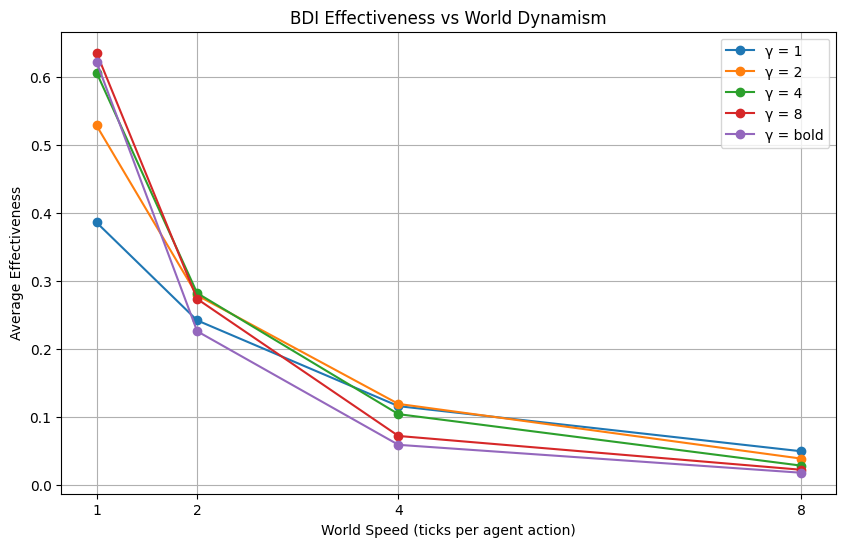

In [35]:
plt.figure(figsize=(10, 6))

for gamma in GAMMA_VALUES:

    data = average_results[
        average_results["gamma"] == gamma
    ]

    plt.plot(
        data["world_speed"],
        data["avg_effectiveness"],
        marker="o",
        label=f"γ = {gamma}"
    )

plt.xlabel("World Speed (ticks per agent action)")
plt.ylabel("Average Effectiveness")
plt.title("BDI Effectiveness vs World Dynamism")
plt.xticks(WORLD_SPEEDS)
plt.grid(True)
plt.legend()

plt.show()

In [36]:
best_gamma = (
    average_results
    .loc[
        average_results
        .groupby("world_speed")["avg_effectiveness"]
        .idxmax()
    ]
    .sort_values("world_speed")
)

best_gamma[
    [
        "world_speed",
        "gamma",
        "avg_effectiveness"
    ]
]

,world_speed,gamma,avg_effectiveness
3,1,8,0.636035
7,2,4,0.282314
11,4,2,0.119271
15,8,1,0.049629


In [37]:
print("BEST γ AT EACH WORLD SPEED")
print("=" * 50)

for _, row in best_gamma.iterrows():

    print(
        f"World speed {int(row['world_speed'])}: "
        f"best γ = {row['gamma']} "
        f"with effectiveness = "
        f"{row['avg_effectiveness']:.4f}"
    )

BEST γ AT EACH WORLD SPEED
World speed 1: best γ = 8 with effectiveness = 0.6360
World speed 2: best γ = 4 with effectiveness = 0.2823
World speed 4: best γ = 2 with effectiveness = 0.1193
World speed 8: best γ = 1 with effectiveness = 0.0496


In [38]:
deliberation_table = average_results.pivot(
    index="world_speed",
    columns="gamma",
    values="avg_deliberation_steps"
)

deliberation_table

gamma,1,2,4,8,bold
world_speed,,,,,
1,627.76,460.00,368.40,310.20,257.96
2,655.20,453.92,329.84,248.32,176.92
4,712.32,488.96,335.24,205.96,129.56
8,821.12,559.80,331.80,180.72,105.48


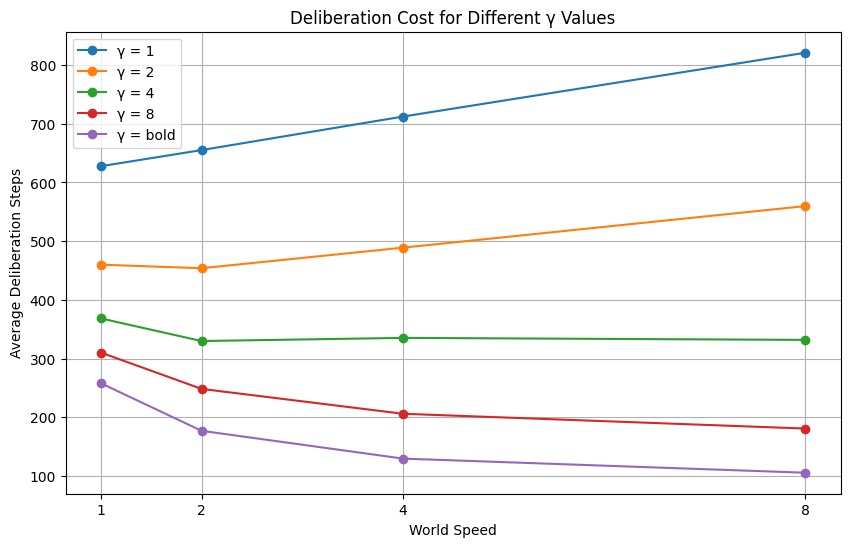

In [39]:
plt.figure(figsize=(10, 6))

for gamma in GAMMA_VALUES:

    data = average_results[
        average_results["gamma"] == gamma
    ]

    plt.plot(
        data["world_speed"],
        data["avg_deliberation_steps"],
        marker="o",
        label=f"γ = {gamma}"
    )

plt.xlabel("World Speed")
plt.ylabel("Average Deliberation Steps")
plt.title("Deliberation Cost for Different γ Values")
plt.xticks(WORLD_SPEEDS)
plt.grid(True)
plt.legend()

plt.show()

# Exercise 2: A Resource-Bounded BDI Agent

The agent has a battery with capacity 40.

- Each movement consumes one unit of battery.
- A charger cell restores the battery to full capacity.
- The `fill-hole` plan is applicable only if the agent has enough
  battery to reach the hole and return to the charger.
- The `recharge` plan is always applicable.

The resource-aware BDI agent selects the nearest hole satisfying
the battery precondition. If no hole satisfies the precondition,
the agent selects the charger as its intention.

We compare this agent with a battery-blind agent that always selects
the nearest hole regardless of its battery level.

In [42]:
class BatteryTileWorld(TileWorld):

    def __init__(
        self,
        size=15,
        hole_probability=0.08,
        min_lifetime=8,
        max_lifetime=25,
        seed=None,
        battery_capacity=40,
        charger_position=(0, 0)
    ):

        super().__init__(
            size=size,
            hole_probability=hole_probability,
            min_lifetime=min_lifetime,
            max_lifetime=max_lifetime,
            seed=seed
        )

        self.battery_capacity = battery_capacity
        self.battery = battery_capacity

        self.charger_position = charger_position

        # Number of agent steps where movement was impossible
        # because the battery was empty.
        self.stranded_steps = 0

    def move_agent(self, new_position):

        # Agent cannot move without battery
        if self.battery <= 0:

            self.stranded_steps += 1

            return False

        # Check whether requested position is adjacent
        if new_position not in self.get_neighbors(
            self.agent_position
        ):
            return False

        # Every movement costs one battery
        self.agent_position = new_position
        self.battery -= 1

        filled = False

        # Fill hole if reached
        if new_position in self.holes:

            del self.holes[new_position]

            self.total_holes_filled += 1

            filled = True

        # Recharge immediately on charger
        if self.agent_position == self.charger_position:

            self.battery = self.battery_capacity

        return filled

In [43]:
class PlanSchema:

    def __init__(self, name, applicability, description):

        self.name = name
        self.applicability = applicability
        self.description = description

    def is_applicable(self, agent, target):

        return self.applicability(
            agent,
            target
        )

In [44]:
def fill_hole_applicable(agent, hole):

    world = agent.world

    current = world.agent_position

    distance_to_hole = world.manhattan_distance(
        current,
        hole
    )

    distance_hole_to_charger = world.manhattan_distance(
        hole,
        world.charger_position
    )

    required_battery = (
        distance_to_hole
        + distance_hole_to_charger
    )

    return (
        world.battery >= required_battery
    )


def recharge_applicable(agent, target):

    return True

In [ ]:
def fill_hole_applicable(agent, hole):

    world = agent.world

    current = world.agent_position

    distance_to_hole = world.manhattan_distance(
        current,
        hole
    )

    distance_hole_to_charger = world.manhattan_distance(
        hole,
        world.charger_position
    )

    required_battery = (
        distance_to_hole
        + distance_hole_to_charger
    )

    return (
        world.battery >= required_battery
    )


def recharge_applicable(agent, target):

    return True

In [45]:
plan_library = {

    "fill-hole": PlanSchema(
        name="fill-hole",
        applicability=fill_hole_applicable,
        description=(
            "Fill a hole only when battery is sufficient "
            "for the trip to the hole and return to charger."
        )
    ),

    "recharge": PlanSchema(
        name="recharge",
        applicability=recharge_applicable,
        description=(
            "Travel to the charger and restore battery."
        )
    )
}

In [46]:
for name, schema in plan_library.items():

    print(f"Plan schema: {name}")
    print(f"Description: {schema.description}")
    print()

Plan schema: fill-hole
Description: Fill a hole only when battery is sufficient for the trip to the hole and return to charger.

Plan schema: recharge
Description: Travel to the charger and restore battery.



In [47]:
class ResourceBoundedBDIAgent(BDIAgent):

    def __init__(
        self,
        world,
        gamma=4
    ):

        super().__init__(
            world=world,
            gamma=gamma
        )

        self.current_plan_schema = None

    # ================================================
    # RESOURCE-AWARE FILTER
    # ================================================

    def filter(self):

        world = self.world

        current = world.agent_position

        feasible_holes = []

        # Check every desired hole
        for hole in self.desires:

            distance_to_hole = (
                world.manhattan_distance(
                    current,
                    hole
                )
            )

            distance_to_charger = (
                world.manhattan_distance(
                    hole,
                    world.charger_position
                )
            )

            required_battery = (
                distance_to_hole
                + distance_to_charger
            )

            # fill-hole precondition
            if world.battery >= required_battery:

                feasible_holes.append(
                    (
                        hole,
                        distance_to_hole,
                        required_battery
                    )
                )

        # --------------------------------------------
        # If a feasible hole exists:
        # choose nearest feasible hole
        # --------------------------------------------

        if feasible_holes:

            feasible_holes.sort(
                key=lambda x: x[1]
            )

            selected_hole = feasible_holes[0][0]

            self.current_plan_schema = "fill-hole"

            return selected_hole

        # --------------------------------------------
        # Otherwise recharge
        # --------------------------------------------

        self.current_plan_schema = "recharge"

        return world.charger_position

    # ================================================
    # PLAN
    # ================================================

    def make_plan(self, intention):

        if intention is None:
            return []

        return shortest_path(
            self.world.agent_position,
            intention,
            self.world.size
        ) or []

    # ================================================
    # EXECUTE ACTION
    # ================================================

    def execute_action(self):

        if not self.plan:
            return False

        next_position = self.plan.pop(0)

        filled = self.world.move_agent(
            next_position
        )

        self.agent_steps += 1
        self.since_reconsideration += 1

        # ------------------------------------------------
        # Hole successfully filled
        # ------------------------------------------------

        if filled:

            achieved = self.intention

            self.events.append(
                f"ACHIEVE: filled hole {achieved}"
            )

            self.intention = None
            self.plan = []
            self.current_plan_schema = None

            self.since_reconsideration = 0

        # ------------------------------------------------
        # Recharge achieved
        # ------------------------------------------------

        elif (
            self.current_plan_schema == "recharge"
            and self.world.agent_position
            == self.world.charger_position
        ):

            self.events.append(
                "ACHIEVE: recharge completed "
                f"(battery = {self.world.battery})"
            )

            self.intention = None
            self.plan = []
            self.current_plan_schema = None

            self.since_reconsideration = 0

        return filled

In [48]:
world = BatteryTileWorld(
    seed=42,
    battery_capacity=40,
    charger_position=(0, 0)
)

agent = ResourceBoundedBDIAgent(
    world=world,
    gamma=4
)

result = agent.run(
    steps=100,
    world_speed=2
)

print("RESULT")
print("=" * 50)

for key, value in result.items():
    print(f"{key}: {value}")

print("\nFinal battery:", world.battery)
print("Stranded steps:", world.stranded_steps)

RESULT
holes_appeared: 17
holes_filled: 5
effectiveness: 0.29411764705882354
agent_steps: 119
deliberation_steps: 43

Final battery: 8
Stranded steps: 0


In [49]:
print("RESOURCE-AWARE BDI EVENT TRACE")
print("=" * 60)

for event in agent.events:
    print(event)

RESOURCE-AWARE BDI EVENT TRACE
COMMIT: (0, 0)
DROP: (0, 0) became unachievable
COMMIT: (4, 10)
ACHIEVE: filled hole (4, 10)
COMMIT: (3, 11)
ACHIEVE: filled hole (3, 11)
COMMIT: (3, 5)
ACHIEVE: filled hole (3, 5)
COMMIT: (5, 2)
ACHIEVE: filled hole (5, 2)
COMMIT: (11, 0)
DROP: (11, 0) became unachievable
COMMIT: (0, 0)
DROP: (0, 0) became unachievable
COMMIT: (0, 0)
DROP: (0, 0) became unachievable
COMMIT: (0, 0)
ACHIEVE: recharge completed (battery = 40)
COMMIT: (0, 0)
SWITCH: (0, 0) -> (12, 5)
DROP: (12, 5) became unachievable
COMMIT: (0, 0)
DROP: (0, 0) became unachievable
COMMIT: (0, 0)
ACHIEVE: recharge completed (battery = 40)
COMMIT: (12, 8)
SWITCH: (12, 8) -> (0, 5)
ACHIEVE: filled hole (0, 5)
COMMIT: (4, 2)
DROP: (4, 2) became unachievable
COMMIT: (0, 0)
DROP: (0, 0) became unachievable
COMMIT: (9, 4)
DROP: (9, 4) became unachievable
COMMIT: (6, 8)
DROP: (6, 8) became unachievable
COMMIT: (0, 0)
DROP: (0, 0) became unachievable
COMMIT: (0, 0)
DROP: (0, 0) became unachievable
CO

In [50]:
class BatteryBlindAgent(BDIAgent):

    def __init__(
        self,
        world,
        gamma=4
    ):

        super().__init__(
            world=world,
            gamma=gamma
        )

    def filter(self):

        if not self.desires:

            return None

        current = self.world.agent_position

        # Always choose nearest hole.
        # Battery is completely ignored.

        return min(
            self.desires,
            key=lambda hole:
                self.world.manhattan_distance(
                    current,
                    hole
                )
        )

In [52]:
def run_resource_comparison(
    seed=42,
    gamma=4,
    world_speed=2,
    steps=600
):

    # -----------------------------------------------
    # Resource-aware agent
    # -----------------------------------------------

    resource_world = BatteryTileWorld(
        seed=seed,
        battery_capacity=40,
        charger_position=(0, 0)
    )

    resource_agent = ResourceBoundedBDIAgent(
        world=resource_world,
        gamma=gamma
    )

    resource_result = resource_agent.run(
        steps=steps,
        world_speed=world_speed
    )

    # -----------------------------------------------
    # Battery-blind agent
    # -----------------------------------------------

    blind_world = BatteryTileWorld(
        seed=seed,
        battery_capacity=40,
        charger_position=(0, 0)
    )

    blind_agent = BatteryBlindAgent(
        world=blind_world,
        gamma=gamma
    )

    blind_result = blind_agent.run(
        steps=steps,
        world_speed=world_speed
    )

    return resource_world, resource_agent, resource_result, \
           blind_world, blind_agent, blind_result

In [53]:
(
    resource_world,
    resource_agent,
    resource_result,
    blind_world,
    blind_agent,
    blind_result
) = run_resource_comparison(
    seed=42,
    gamma=4,
    world_speed=2,
    steps=600
)

In [54]:
comparison_df = pd.DataFrame([
    {
        "Agent": "Resource-Bounded BDI",
        "Holes Appeared":
            resource_result["holes_appeared"],
        "Holes Filled":
            resource_result["holes_filled"],
        "Effectiveness":
            resource_result["effectiveness"],
        "Stranded Steps":
            resource_world.stranded_steps
    },
    {
        "Agent": "Battery-Blind",
        "Holes Appeared":
            blind_result["holes_appeared"],
        "Holes Filled":
            blind_result["holes_filled"],
        "Effectiveness":
            blind_result["effectiveness"],
        "Stranded Steps":
            blind_world.stranded_steps
    }
])

comparison_df

,Agent,Holes Appeared,Holes Filled,Effectiveness,Stranded Steps
0,Resource-Bounded BDI,96,16,0.166667,0
1,Battery-Blind,93,4,0.043011,397


In [55]:
def run_resource_experiment(
    num_seeds=25,
    steps=600,
    world_speed=2,
    gamma=4
):

    results = []

    for seed in range(num_seeds):

        (
            resource_world,
            resource_agent,
            resource_result,
            blind_world,
            blind_agent,
            blind_result
        ) = run_resource_comparison(
            seed=seed,
            gamma=gamma,
            world_speed=world_speed,
            steps=steps
        )

        results.append({
            "seed": seed,

            "resource_holes_filled":
                resource_result["holes_filled"],

            "resource_effectiveness":
                resource_result["effectiveness"],

            "resource_stranded":
                resource_world.stranded_steps,

            "blind_holes_filled":
                blind_result["holes_filled"],

            "blind_effectiveness":
                blind_result["effectiveness"],

            "blind_stranded":
                blind_world.stranded_steps
        })

    return pd.DataFrame(results)

In [56]:
resource_results = run_resource_experiment(
    num_seeds=25,
    steps=600,
    world_speed=2,
    gamma=4
)

resource_results.head()

,seed,resource_holes_filled,resource_effectiveness,resource_stranded,blind_holes_filled,blind_effectiveness,blind_stranded
0,0,27,0.238938,0,4,0.036036,419
1,1,15,0.176471,0,2,0.023810,389
2,2,21,0.203883,0,2,0.020000,397
3,3,16,0.160000,0,1,0.010000,381
4,4,21,0.207921,0,4,0.039604,420


,Agent,Average Holes Filled,Average Effectiveness,Average Stranded Steps
0,Resource-Bounded BDI,19.68,0.187410,0.00
1,Battery-Blind,2.84,0.027313,417.72


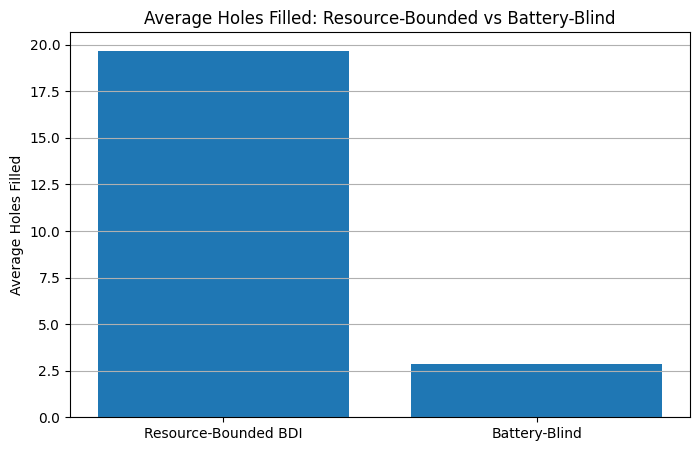

In [58]:
plt.figure(figsize=(8, 5))

plt.bar(
    summary["Agent"],
    summary["Average Holes Filled"]
)

plt.ylabel("Average Holes Filled")
plt.title("Average Holes Filled: Resource-Bounded vs Battery-Blind")
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

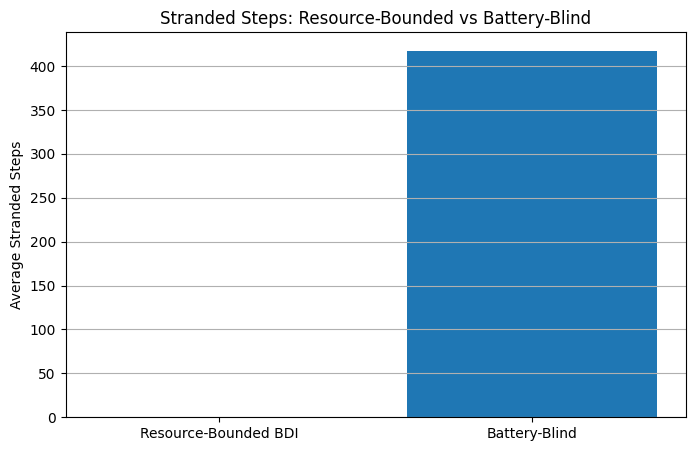

In [59]:
plt.figure(figsize=(8, 5))

plt.bar(
    summary["Agent"],
    summary["Average Stranded Steps"]
)

plt.ylabel("Average Stranded Steps")
plt.title("Stranded Steps: Resource-Bounded vs Battery-Blind")
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

In [60]:
def show_battery_requirement(
    world,
    hole
):

    distance_to_hole = world.manhattan_distance(
        world.agent_position,
        hole
    )

    distance_to_charger = world.manhattan_distance(
        hole,
        world.charger_position
    )

    required = (
        distance_to_hole +
        distance_to_charger
    )

    print("Current position:", world.agent_position)
    print("Hole:", hole)
    print("Charger:", world.charger_position)

    print(
        "Distance to hole:",
        distance_to_hole
    )

    print(
        "Distance hole → charger:",
        distance_to_charger
    )

    print(
        "Required battery:",
        required
    )

    print(
        "Available battery:",
        world.battery
    )

    print(
        "fill-hole applicable:",
        world.battery >= required
    )

In [63]:
def show_battery_requirement(world, hole):

    distance_to_hole = world.manhattan_distance(
        world.agent_position,
        hole
    )

    distance_to_charger = world.manhattan_distance(
        hole,
        world.charger_position
    )

    required = (
        distance_to_hole +
        distance_to_charger
    )

    print("Current position:", world.agent_position)
    print("Hole:", hole)
    print("Charger:", world.charger_position)

    print("Distance to hole:", distance_to_hole)
    print("Distance hole → charger:", distance_to_charger)
    print("Required battery:", required)
    print("Available battery:", world.battery)

    print(
        "fill-hole applicable:",
        world.battery >= required
    )

In [64]:
test_world = BatteryTileWorld(
    seed=10,
    battery_capacity=40,
    charger_position=(0, 0)
)

# Generate a few holes
for _ in range(5):
    test_world.add_hole()

print("Current position:", test_world.agent_position)
print("Battery:", test_world.battery)
print("Charger:", test_world.charger_position)
print("Holes:", test_world.get_hole_positions())
for hole in test_world.get_hole_positions():

    print("\n" + "=" * 50)

    show_battery_requirement(
        test_world,
        hole
    )

Current position: (7, 7)
Battery: 40
Charger: (0, 0)
Holes: [(9, 12), (7, 4), (10, 0), (3, 7), (14, 3)]

Current position: (7, 7)
Hole: (9, 12)
Charger: (0, 0)
Distance to hole: 7
Distance hole → charger: 21
Required battery: 28
Available battery: 40
fill-hole applicable: True

Current position: (7, 7)
Hole: (7, 4)
Charger: (0, 0)
Distance to hole: 3
Distance hole → charger: 11
Required battery: 14
Available battery: 40
fill-hole applicable: True

Current position: (7, 7)
Hole: (10, 0)
Charger: (0, 0)
Distance to hole: 10
Distance hole → charger: 10
Required battery: 20
Available battery: 40
fill-hole applicable: True

Current position: (7, 7)
Hole: (3, 7)
Charger: (0, 0)
Distance to hole: 4
Distance hole → charger: 10
Required battery: 14
Available battery: 40
fill-hole applicable: True

Current position: (7, 7)
Hole: (14, 3)
Charger: (0, 0)
Distance to hole: 11
Distance hole → charger: 17
Required battery: 28
Available battery: 40
fill-hole applicable: True


In [66]:
def run_battery_parameter_sweep(
    gamma_values=[1, 2, 4, 8, "bold"],
    world_speeds=[1, 2, 4, 8],
    num_seeds=25,
    steps=600
):

    results = []

    total_runs = (
        2
        * len(gamma_values)
        * len(world_speeds)
        * num_seeds
    )

    current_run = 0

    for gamma in gamma_values:

        for world_speed in world_speeds:

            for seed in range(num_seeds):

                # ==========================================
                # RESOURCE-BOUNDED BDI
                # ==========================================

                resource_world = BatteryTileWorld(
                    seed=seed,
                    battery_capacity=40,
                    charger_position=(0, 0)
                )

                resource_agent = ResourceBoundedBDIAgent(
                    world=resource_world,
                    gamma=gamma
                )

                resource_result = resource_agent.run(
                    steps=steps,
                    world_speed=world_speed
                )

                # ==========================================
                # BATTERY-BLIND
                # ==========================================

                blind_world = BatteryTileWorld(
                    seed=seed,
                    battery_capacity=40,
                    charger_position=(0, 0)
                )

                blind_agent = BatteryBlindAgent(
                    world=blind_world,
                    gamma=gamma
                )

                blind_result = blind_agent.run(
                    steps=steps,
                    world_speed=world_speed
                )

                # ==========================================
                # STORE RESULTS
                # ==========================================

                results.append({

                    "gamma": gamma,
                    "world_speed": world_speed,
                    "seed": seed,

                    "resource_holes_filled":
                        resource_result["holes_filled"],

                    "resource_effectiveness":
                        resource_result["effectiveness"],

                    "resource_stranded":
                        resource_world.stranded_steps,

                    "blind_holes_filled":
                        blind_result["holes_filled"],

                    "blind_effectiveness":
                        blind_result["effectiveness"],

                    "blind_stranded":
                        blind_world.stranded_steps
                })

                current_run += 2

                if current_run % 100 == 0:
                    print(
                        f"Completed "
                        f"{current_run}/{total_runs}"
                    )

    return pd.DataFrame(results)

In [67]:
battery_sweep_df = run_battery_parameter_sweep(
    gamma_values=[1, 2, 4, 8, "bold"],
    world_speeds=[1, 2, 4, 8],
    num_seeds=25,
    steps=600
)

print("Total rows:", len(battery_sweep_df))

Completed 100/1000
Completed 200/1000
Completed 300/1000
Completed 400/1000
Completed 500/1000
Completed 600/1000
Completed 700/1000
Completed 800/1000
Completed 900/1000
Completed 1000/1000
Total rows: 500


In [68]:
battery_sweep_df.groupby(
    ["gamma", "world_speed"]
).size()

gamma  world_speed
1      1              25
       2              25
       4              25
       8              25
2      1              25
       2              25
       4              25
       8              25
4      1              25
       2              25
       4              25
       8              25
8      1              25
       2              25
       4              25
       8              25
bold   1              25
       2              25
       4              25
       8              25
dtype: int64

In [69]:
battery_average = (
    battery_sweep_df
    .groupby(["gamma", "world_speed"])
    .agg(
        resource_avg_filled=(
            "resource_holes_filled",
            "mean"
        ),

        resource_avg_effectiveness=(
            "resource_effectiveness",
            "mean"
        ),

        resource_avg_stranded=(
            "resource_stranded",
            "mean"
        ),

        blind_avg_filled=(
            "blind_holes_filled",
            "mean"
        ),

        blind_avg_effectiveness=(
            "blind_effectiveness",
            "mean"
        ),

        blind_avg_stranded=(
            "blind_stranded",
            "mean"
        )
    )
    .reset_index()
)

battery_average

,gamma,world_speed,resource_avg_filled,resource_avg_effectiveness,resource_avg_stranded,blind_avg_filled,blind_avg_effectiveness,blind_avg_stranded
0,1,1,22.64,0.276120,0.0,4.04,0.053914,305.68
1,1,2,20.96,0.158281,0.0,3.44,0.027025,351.48
2,1,4,19.00,0.083308,0.0,2.72,0.012355,378.20
3,1,8,15.68,0.036918,0.0,2.16,0.005175,395.56
4,2,1,24.80,0.378822,0.0,4.00,0.063669,353.64
5,2,2,21.52,0.188327,0.0,3.48,0.031166,386.88
6,2,4,17.20,0.083140,0.0,2.56,0.012615,411.68
7,2,8,12.40,0.030652,0.0,1.48,0.003669,439.72
8,4,1,22.68,0.400529,0.0,4.00,0.072760,385.72
9,4,2,19.68,0.187410,0.0,2.84,0.027313,417.72


In [70]:
resource_effectiveness_table = (
    battery_average
    .pivot(
        index="world_speed",
        columns="gamma",
        values="resource_avg_effectiveness"
    )
)

resource_effectiveness_table.round(4)

gamma,1,2,4,8,bold
world_speed,,,,,
1,0.2761,0.3788,0.4005,0.4229,0.3934
2,0.1583,0.1883,0.1874,0.1704,0.1340
4,0.0833,0.0831,0.0650,0.0473,0.0370
8,0.0369,0.0307,0.0218,0.0139,0.0139


In [71]:
blind_effectiveness_table = (
    battery_average
    .pivot(
        index="world_speed",
        columns="gamma",
        values="blind_avg_effectiveness"
    )
)

blind_effectiveness_table.round(4)

gamma,1,2,4,8,bold
world_speed,,,,,
1,0.0539,0.0637,0.0728,0.0734,0.0701
2,0.0270,0.0312,0.0273,0.0273,0.0261
4,0.0124,0.0126,0.0096,0.0075,0.0066
8,0.0052,0.0037,0.0024,0.0028,0.0024


In [72]:
resource_stranded_table = (
    battery_average
    .pivot(
        index="world_speed",
        columns="gamma",
        values="resource_avg_stranded"
    )
)

resource_stranded_table.round(2)

gamma,1,2,4,8,bold
world_speed,,,,,
1,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0


In [73]:
blind_stranded_table = (
    battery_average
    .pivot(
        index="world_speed",
        columns="gamma",
        values="blind_avg_stranded"
    )
)

blind_stranded_table.round(2)

gamma,1,2,4,8,bold
world_speed,,,,,
1,305.68,353.64,385.72,410.24,431.04
2,351.48,386.88,417.72,440.24,457.04
4,378.20,411.68,446.24,480.32,491.08
8,395.56,439.72,485.84,512.72,518.72


In [74]:
battery_average["effectiveness_improvement"] = (
    battery_average["resource_avg_effectiveness"]
    /
    battery_average["blind_avg_effectiveness"]
)

battery_average[
    [
        "gamma",
        "world_speed",
        "resource_avg_effectiveness",
        "blind_avg_effectiveness",
        "effectiveness_improvement"
    ]
].round(4)

,gamma,world_speed,resource_avg_effectiveness,blind_avg_effectiveness,effectiveness_improvement
0,1,1,0.2761,0.0539,5.1215
1,1,2,0.1583,0.0270,5.8569
2,1,4,0.0833,0.0124,6.7429
3,1,8,0.0369,0.0052,7.1333
4,2,1,0.3788,0.0637,5.9499
5,2,2,0.1883,0.0312,6.0426
6,2,4,0.0831,0.0126,6.5907
7,2,8,0.0307,0.0037,8.3547
8,4,1,0.4005,0.0728,5.5048
9,4,2,0.1874,0.0273,6.8615


In [75]:
resource_best_gamma = (
    battery_average
    .loc[
        battery_average
        .groupby("world_speed")
        ["resource_avg_effectiveness"]
        .idxmax()
    ]
    .sort_values("world_speed")
)

resource_best_gamma[
    [
        "world_speed",
        "gamma",
        "resource_avg_effectiveness"
    ]
].round(4)

,world_speed,gamma,resource_avg_effectiveness
12,1,8,0.4229
5,2,2,0.1883
2,4,1,0.0833
3,8,1,0.0369


In [76]:
blind_best_gamma = (
    battery_average
    .loc[
        battery_average
        .groupby("world_speed")
        ["blind_avg_effectiveness"]
        .idxmax()
    ]
    .sort_values("world_speed")
)

blind_best_gamma[
    [
        "world_speed",
        "gamma",
        "blind_avg_effectiveness"
    ]
].round(4)

,world_speed,gamma,blind_avg_effectiveness
12,1,8,0.0734
5,2,2,0.0312
6,4,2,0.0126
3,8,1,0.0052


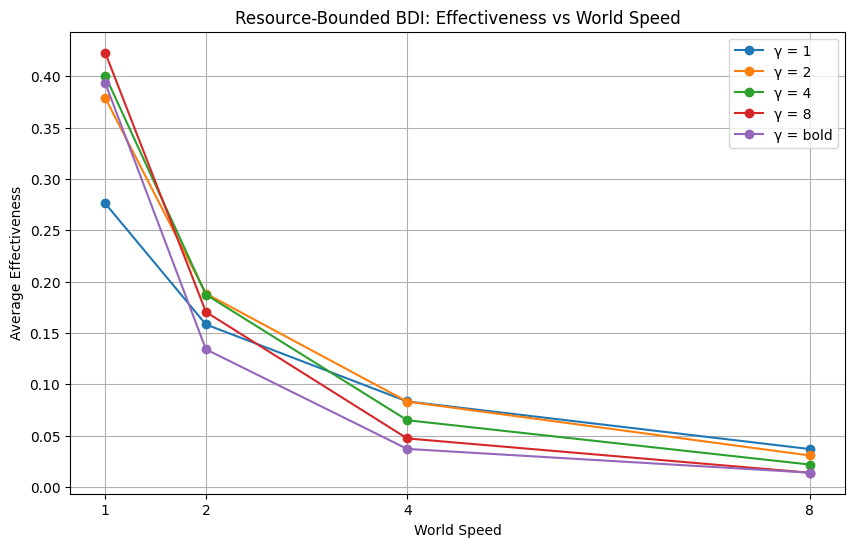

In [77]:
plt.figure(figsize=(10, 6))

for gamma in [1, 2, 4, 8, "bold"]:

    data = battery_average[
        battery_average["gamma"] == gamma
    ].sort_values("world_speed")

    plt.plot(
        data["world_speed"],
        data["resource_avg_effectiveness"],
        marker="o",
        label=f"γ = {gamma}"
    )

plt.xlabel("World Speed")
plt.ylabel("Average Effectiveness")
plt.title(
    "Resource-Bounded BDI: Effectiveness vs World Speed"
)
plt.xticks([1, 2, 4, 8])
plt.grid(True)
plt.legend()

plt.show()

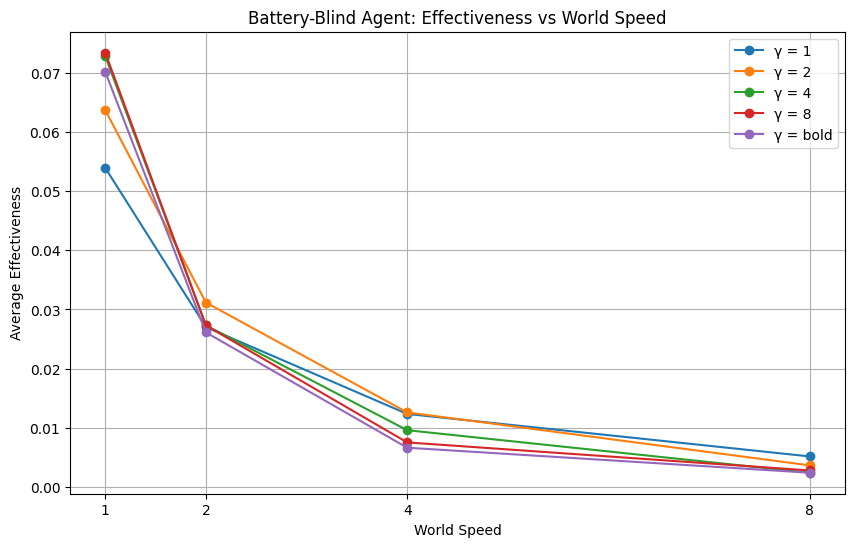

In [78]:
plt.figure(figsize=(10, 6))

for gamma in [1, 2, 4, 8, "bold"]:

    data = battery_average[
        battery_average["gamma"] == gamma
    ].sort_values("world_speed")

    plt.plot(
        data["world_speed"],
        data["blind_avg_effectiveness"],
        marker="o",
        label=f"γ = {gamma}"
    )

plt.xlabel("World Speed")
plt.ylabel("Average Effectiveness")
plt.title(
    "Battery-Blind Agent: Effectiveness vs World Speed"
)
plt.xticks([1, 2, 4, 8])
plt.grid(True)
plt.legend()

plt.show()

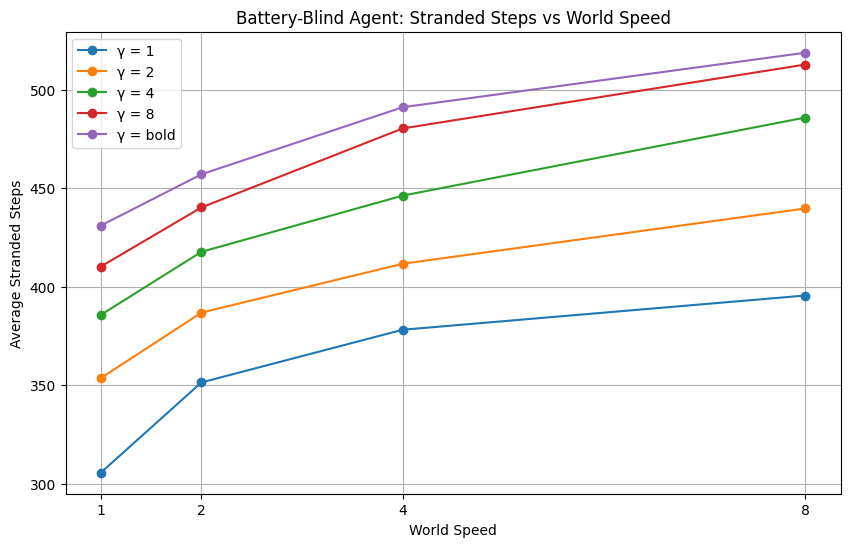

In [79]:
plt.figure(figsize=(10, 6))

for gamma in [1, 2, 4, 8, "bold"]:

    data = battery_average[
        battery_average["gamma"] == gamma
    ].sort_values("world_speed")

    plt.plot(
        data["world_speed"],
        data["blind_avg_stranded"],
        marker="o",
        label=f"γ = {gamma}"
    )

plt.xlabel("World Speed")
plt.ylabel("Average Stranded Steps")
plt.title(
    "Battery-Blind Agent: Stranded Steps vs World Speed"
)
plt.xticks([1, 2, 4, 8])
plt.grid(True)
plt.legend()

plt.show()

In [80]:
battery_average["filled_difference"] = (
    battery_average["resource_avg_filled"]
    -
    battery_average["blind_avg_filled"]
)

battery_average[
    [
        "gamma",
        "world_speed",
        "resource_avg_filled",
        "blind_avg_filled",
        "filled_difference"
    ]
].round(2)

,gamma,world_speed,resource_avg_filled,blind_avg_filled,filled_difference
0,1,1,22.64,4.04,18.60
1,1,2,20.96,3.44,17.52
2,1,4,19.00,2.72,16.28
3,1,8,15.68,2.16,13.52
4,2,1,24.80,4.00,20.80
5,2,2,21.52,3.48,18.04
6,2,4,17.20,2.56,14.64
7,2,8,12.40,1.48,10.92
8,4,1,22.68,4.00,18.68
9,4,2,19.68,2.84,16.84


In [81]:
overall_battery_summary = pd.DataFrame({

    "Metric": [
        "Average holes filled",
        "Average effectiveness",
        "Average stranded steps"
    ],

    "Resource-Bounded BDI": [
        battery_sweep_df[
            "resource_holes_filled"
        ].mean(),

        battery_sweep_df[
            "resource_effectiveness"
        ].mean(),

        battery_sweep_df[
            "resource_stranded"
        ].mean()
    ],

    "Battery-Blind": [
        battery_sweep_df[
            "blind_holes_filled"
        ].mean(),

        battery_sweep_df[
            "blind_effectiveness"
        ].mean(),

        battery_sweep_df[
            "blind_stranded"
        ].mean()
    ]
})

overall_battery_summary.round(4)

,Metric,Resource-Bounded BDI,Battery-Blind
0,Average holes filled,15.8080,2.5300
1,Average effectiveness,0.1572,0.0269
2,Average stranded steps,0.0000,424.9880
